# <p style="color:pink">Dataset used : FILL THIS IN
induced in-vitro transition process, the Epithelial-to-Mesenchymal Transition (EMT) of human A549 cells treated with TGF-β or TNF or EGF for different durations. Single-cell RNA-seq profiles of 12 EMT time course experiments spanning multiple cell lines and EMT inducers, and independent kinase inhibitor screens for each. This notebook uses the A549 (lung carcinoma) cell line data. 
## <p style="color:coral">Reference : 
D. P. Cook and B. C. Vanderhyden, Context specificity of the EMT transcriptional response, Nat. Commun. 11, 2142 (2020). 
GSE147405

### <p style="color:pink">Libraries and dependencies</p>

In [ ]:
import mygene
import pyreadr
import numpy as np
from scipy.sparse.csgraph import connected_components
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

### <p style="color:pink">Load data

In [2]:
import scanpy as sc

adata = sc.read('/home/csb/Saloni/SCENT/data/MCF10A_dose.h5ad')

In [4]:
print(adata)
print(adata.var_names[:20])
print(adata.X.shape)
print(adata.var.head())

AnnData object with n_obs × n_vars = 8882 × 33694
    obs: 'GBC_annot', 'Values', 'Dose_pM'
Index(['ENSG00000243485', 'ENSG00000237613', 'ENSG00000186092',
       'ENSG00000238009', 'ENSG00000239945', 'ENSG00000239906',
       'ENSG00000241599', 'ENSG00000279928', 'ENSG00000279457',
       'ENSG00000228463', 'ENSG00000236743', 'ENSG00000236601',
       'ENSG00000237094', 'ENSG00000278566', 'ENSG00000230021',
       'ENSG00000235146', 'ENSG00000273547', 'ENSG00000229905',
       'ENSG00000237491', 'ENSG00000177757'],
      dtype='object')
(8882, 33694)
Empty DataFrame
Columns: []
Index: [ENSG00000243485, ENSG00000237613, ENSG00000186092, ENSG00000238009, ENSG00000239945]


In [5]:
print(adata.obs['Dose_pM'].unique())

[ 12.5  50.  200.    0.  800.  100.   25.  400. ]


In [6]:
print(type(adata.X))
print(adata.X.shape)

if hasattr(adata.X, "toarray"):
    print(adata.X[:5, :5].toarray())
else:
    print(adata.X[:5, :5])

<class 'scipy.sparse._csc.csc_matrix'>
(8882, 33694)
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


In [7]:
print(adata.layers.keys())
print(adata.raw)

KeysView(Layers with keys: )
None


### <p style="color:pink">Load gene lists</p>

In [8]:
# ------------------------------------------------------------
# Load Tan2014 gene signatures
# ------------------------------------------------------------

def load_gene_list(path):
    with open(path) as f:
        return [line.strip() for line in f if line.strip()]


tan_epi = load_gene_list(
    "/home/csb/Saloni/SCENT/data/Signatures/Tan2014_Epithelial.txt"
)

tan_mes = load_gene_list(
    "/home/csb/Saloni/SCENT/data/Signatures/Tan2014_Mesenchymal.txt"
)

print("Tan2014 epithelial genes:", len(tan_epi))
print("Tan2014 mesenchymal genes:", len(tan_mes))
print("Combined:", len(set(tan_epi + tan_mes)))

Tan2014 epithelial genes: 170
Tan2014 mesenchymal genes: 46
Combined: 216


In [10]:
# ------------------------------------------------------------
# Map Tan2014 gene symbols -> Ensembl IDs
# ------------------------------------------------------------

mg = mygene.MyGeneInfo()

all_signature_genes = list(set(tan_epi + tan_mes))

query = mg.querymany(
    all_signature_genes,
    scopes="symbol",
    fields="ensembl.gene",
    species="human",
    returnall=True
)

symbol_to_ensembl = {}

for q in query["out"]:
    if "ensembl" in q:

        ens = q["ensembl"]

        # MyGene can sometimes return multiple Ensembl entries
        if isinstance(ens, list):
            ens = ens[0]

        if isinstance(ens, dict):
            ens = ens.get("gene")

        if ens is not None:
            symbol_to_ensembl[q["query"]] = ens

12 input query terms found no hit:	['C1orf106', 'TMEM30B', 'SLC9A3R1', 'LEPRE1', 'C4orf19', 'GPR56', 'C10orf116', 'KDELC1', 'LHFP', 'C1


### <p style="color:pink">Check presence of epi and mes lists from the gene lists in our data</p>

In [11]:
epi_genes = [
    symbol_to_ensembl[g]
    for g in tan_epi
    if g in symbol_to_ensembl
    and symbol_to_ensembl[g] in adata.var_names
]

mes_genes = [
    symbol_to_ensembl[g]
    for g in tan_mes
    if g in symbol_to_ensembl
    and symbol_to_ensembl[g] in adata.var_names
]

print("E genes present:", len(epi_genes), "/", len(tan_epi))
print("M genes present:", len(mes_genes), "/", len(tan_mes))
print("Total present:", len(set(epi_genes + mes_genes)))

E genes present: 156 / 170
M genes present: 42 / 46
Total present: 198


### <p style="color:pink">Calculate ks epi and ks mes scores</p>

In [12]:
sc.tl.score_genes(
    adata,
    epi_genes,
    score_name="KS_epi"
)

sc.tl.score_genes(
    adata,
    mes_genes,
    score_name="KS_mes"
)

### <p style="color:pink">Classify into phenotypes -- Divide population in four quadrants based on the medians of our ks_epi and ks_mes scores</p>

In [13]:
# Define the median epithelial and mesenchymal scores as thresholds to divide
# cells into four phenotypic quadrants based on relative EMT signature activity.
epi_thresh = adata.obs["KS_epi"].median()
mes_thresh = adata.obs["KS_mes"].median()


def classify(row):

    e = row["KS_epi"] > epi_thresh
    m = row["KS_mes"] > mes_thresh

    if e and not m:
        return "epithelial"

    if m and not e:
        return "mesenchymal"

    if e and m:
        return "hybrid"

    return "undetermined"


adata.obs["phenotype"] = adata.obs.apply(
    classify,
    axis=1
)

In [14]:
print(
    adata.obs["phenotype"].value_counts()
)

phenotype
mesenchymal     2727
epithelial      2726
undetermined    1715
hybrid          1714
Name: count, dtype: int64


In [15]:
print(
    pd.crosstab(
        adata.obs["Dose_pM"],
        adata.obs["phenotype"]
    )
)

phenotype  epithelial  hybrid  mesenchymal  undetermined
Dose_pM                                                 
0.0              1203     104           12            18
12.5              719     239          236           228
25.0              259     215          350           176
50.0              261     277          272           210
100.0              73     321          601           177
200.0              52     297          495           176
400.0              54      97          350           361
800.0             105     164          411           369


### <p style="color:pink">Load PPI network to run SCENT analysis</p>

In [16]:
result = pyreadr.read_r("/home/csb/Saloni/SCENT/data/net17Jan16.rda")
print(result.keys())                    # confirm the actual object name it loaded
net_df = result['net17Jan16.m']          # adjust key if pyreadr reports something else

net_gene_ids = net_df.index.astype(str).tolist()   # Entrez IDs, as strings
A_full = net_df.values.astype(np.float32)

print(A_full.shape)
assert np.allclose(A_full, A_full.T)
assert np.all(np.diag(A_full) == 0)

odict_keys(['net17Jan16.m'])
(11751, 11751)


In [17]:
mg = mygene.MyGeneInfo()

query = mg.querymany(
    adata.var_names.tolist(),
    scopes="ensembl.gene",
    fields="entrezgene",
    species="human",
    returnall=True
)

ensembl_to_entrez = {}

for q in query["out"]:
    if "entrezgene" in q:
        ensembl = q["query"]
        ensembl_to_entrez[ensembl] = str(q["entrezgene"])

print(
    f"Mapped: {len(ensembl_to_entrez)} / {adata.n_vars}"
)

24 input query terms found dup hits:	[('ENSG00000117262', 2), ('ENSG00000188092', 2), ('ENSG00000228044', 2), ('ENSG00000226506', 2), ('E
1626 input query terms found no hit:	['ENSG00000238009', 'ENSG00000236743', 'ENSG00000278566', 'ENSG00000273547', 'ENSG00000230699', 'ENS


Mapped: 23951 / 33694


### <p style="color:pink">Map expression onto the the network</p>

In [18]:
common_ensembl = [
    gene
    for gene in adata.var_names
    if gene in ensembl_to_entrez
    and ensembl_to_entrez[gene] in net_gene_ids
]

common_entrez = [
    ensembl_to_entrez[gene]
    for gene in common_ensembl
]

entrez_idx = [
    net_gene_ids.index(e)
    for e in common_entrez
]

A_sub = A_full[np.ix_(entrez_idx, entrez_idx)]

In [19]:
n_comp, labels = connected_components(
    A_sub,
    directed=False
)

largest = np.bincount(labels).argmax()
mask = labels == largest

A_final = A_sub[mask][:, mask]

final_genes = [
    gene
    for gene, m in zip(common_ensembl, mask)
    if m
]

print(f"Final network-aligned gene set: {len(final_genes)} genes")

Final network-aligned gene set: 11665 genes


##### <p style="color:coral">Network alignment</p>

The PPI network is represented by an adjacency matrix \(A\), where

\[
A_{ij} =
\begin{cases}
1 & \text{if genes } i \text{ and } j \text{ interact}\\
0 & \text{otherwise.}
\end{cases}
\]

We first restrict \(A\) to genes that are present in both the scRNA-seq dataset and the PPI network:

\[
A_{\mathrm{sub}} = A[I,I]
\]

where \(I\) is the set of genes common to the expression data and the PPI network.

SCENT models signalling as information flow through this network, so we retain the **largest connected component**. This ensures that the subsequent signalling-entropy calculation is performed on a single connected network rather than on disconnected subgraphs.

### <p style="color:pink">Preparing expression matrix</p>

In [21]:
# Restrict the AnnData object to genes that are present in the final PPI network.
adata_sub = adata[:, final_genes].copy()

# Convert the expression matrix to a dense NumPy array if it is stored as a sparse matrix.
X_raw = adata_sub.X.toarray() if hasattr(adata_sub.X, 'toarray') else adata_sub.X

X_log = np.log(X_raw + 1).astype(np.float32)

##### <p style="color:coral">Preparing the expression matrix</p>

The expression matrix is first restricted to the genes retained in the final PPI network, ensuring that every expression value corresponds to a node in the signalling network.

A logarithmic transformation is then applied:

\[
X'_{ij} = \log(X_{ij} + 1.1)
\]

where \(X_{ij}\) is the expression of gene \(j\) in cell \(i\). The pseudocount prevents \(\log(0)\) and the transformation reduces the influence of highly expressed genes while preserving differences in expression.

In [22]:
def compute_CCAT_vectorized(X, A):
    """X: (n_cells, n_genes) log-normalized expression.
       A: (n_genes, n_genes) adjacency matrix, same gene order as X's columns."""
    k = A.sum(axis=1)                        # node degree, (n_genes,)
    k_c = k - k.mean()
    X_c = X - X.mean(axis=1, keepdims=True)

    cov = X_c @ k_c
    std_x = np.sqrt((X_c ** 2).sum(axis=1))
    std_k = np.sqrt((k_c ** 2).sum())

    return cov / (std_x * std_k)

adata.obs['CCAT'] = compute_CCAT_vectorized(X_log, A_final)
print(adata.obs['CCAT'].describe())

count    8882.000000
mean        0.407154
std         0.032258
min         0.312202
25%         0.383150
50%         0.409004
75%         0.431851
max         0.496203
Name: CCAT, dtype: float64


##### <p style="color:coral">Mathematical interpretation</p>

For each cell (c), we have an expression vector

[
\mathbf{x}c = (x{c1},x_{c2},...,x_{cn})
]

and a PPI-network degree vector

[
\mathbf{k} = (k_1,k_2,...,k_n)
]

where (k_i) is the number of interaction partners of gene (i).

The CCAT score is essentially the Pearson correlation between these two vectors:

[
\mathrm{CCAT}c =
\frac{
\sum_i (x{ci}-\bar{x}c)(k_i-\bar{k})
}{
\sqrt{\sum_i(x{ci}-\bar{x}_c)^2}
\sqrt{\sum_i(k_i-\bar{k})^2}
}
]

So CCAT asks:

##### <p style="color:grey">Does this cell preferentially express genes that occupy highly connected positions in the signalling network?</p>

A high positive CCAT means that highly connected genes tend to have relatively high expression in that cell. A lower or negative CCAT indicates weaker or opposite correspondence between expression and network connectivity.

The important distinction from signalling entropy is that CCAT does not measure how uniformly signalling is distributed across the network. Instead, it measures the correlation between expression and network topology.

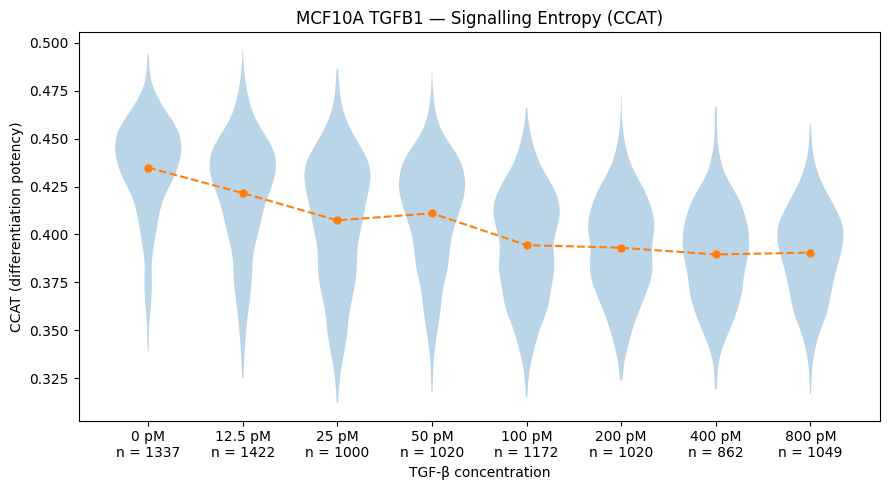

In [23]:
dose_order = [
    0.0,
    12.5,
    25.0,
    50.0,
    100.0,
    200.0,
    400.0,
    800.0
]

# ------------------------------------------------------------
# CCAT values for each dose
# ------------------------------------------------------------

ccat_groups = [
    adata.obs.loc[
        adata.obs["Dose_pM"] == dose,
        "CCAT"
    ].dropna().values
    for dose in dose_order
]

# Mean CCAT at each dose
ccat_means = [
    np.mean(group)
    for group in ccat_groups
]

# Number of cells
cell_counts = (
    adata.obs["Dose_pM"]
    .value_counts()
    .reindex(dose_order)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(dose_order))

# Simple violin
ax.violinplot(
    ccat_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Mean trajectory
ax.plot(
    positions,
    ccat_means,
    "o--",
    linewidth=1.5,
    markersize=5
)

# X-axis labels
labels = [
    f"{dose:g} pM\nn = {int(cell_counts.loc[dose])}"
    for dose in dose_order
]

ax.set_xticks(positions)
ax.set_xticklabels(labels)

ax.set_xlabel("TGF-β concentration")
ax.set_ylabel("CCAT (differentiation potency)")

ax.set_title("MCF10A TGFB1 — Signalling Entropy (CCAT)")

plt.tight_layout()
plt.show()

##### <p style="color:coral">Interpretation</p>

For each time point, the violin represents the distribution of CCAT values across individual cells, while the dashed trajectory connects the mean CCAT values.

CCAT is a transcriptome–connectome correlation measure: it quantifies the extent to which the expression profile of a cell is correlated with the connectivity (degree) of genes in the PPI network. Changes in the mean CCAT across time therefore provide an estimate of changes in signalling-network organization associated with differentiation.

The number of cells (\(n\)) is shown for each time point because differences in sample size can affect the apparent stability of the estimated distribution and mean.

### <p style="color:pink">Statistical Test</p>

In [24]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# TUKEY TEST — CCAT
# ============================================================

tukey_ccat = pairwise_tukeyhsd(
    endog=adata.obs["CCAT"],
    groups=adata.obs["Dose_pM"],
    alpha=0.05
)

print(tukey_ccat)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   0.0   12.5  -0.0133    0.0 -0.0165 -0.0101   True
   0.0   25.0  -0.0275    0.0 -0.0311  -0.024   True
   0.0   50.0  -0.0238    0.0 -0.0274 -0.0203   True
   0.0  100.0  -0.0404    0.0 -0.0438  -0.037   True
   0.0  200.0  -0.0418    0.0 -0.0453 -0.0383   True
   0.0  400.0  -0.0453    0.0  -0.049 -0.0416   True
   0.0  800.0  -0.0443    0.0 -0.0478 -0.0408   True
  12.5   25.0  -0.0142    0.0 -0.0177 -0.0107   True
  12.5   50.0  -0.0105    0.0  -0.014  -0.007   True
  12.5  100.0  -0.0271    0.0 -0.0305 -0.0238   True
  12.5  200.0  -0.0285    0.0  -0.032  -0.025   True
  12.5  400.0   -0.032    0.0 -0.0357 -0.0283   True
  12.5  800.0   -0.031    0.0 -0.0345 -0.0276   True
  25.0   50.0   0.0037  0.061 -0.0001  0.0075  False
  25.0  100.0  -0.0129    0.0 -0.0165 -0.0092   True
  25.0  200.0  -0.0143    0.0 -0.0181 -0.0105 

##### <p style="color:coral">Tukey's HSD post-hoc test -->

Tukey's Honestly Significant Difference (HSD) test performs all pairwise comparisons between dose points after considering the variability within groups.

For two dose points \(i\) and \(j\), the test evaluates whether their mean CCAT scores differ:

\[
H_0: \mu_i = \mu_j
\]

\[
H_A: \mu_i \neq \mu_j
\]

The test accounts for the fact that many pairwise comparisons are being performed simultaneously, controlling the **family-wise Type I error rate** at \(\alpha = 0.05\).

The output reports the mean difference, confidence interval, and adjusted significance decision for each pair of time points. A `reject = True` result indicates a statistically significant difference in mean CCAT between those two dosages.

In [26]:
# ============================================================
# EXTRACT TUKEY RESULTS
# ============================================================

tukey_ccat_df = pd.DataFrame(
    data=tukey_ccat._results_table.data[1:],
    columns=tukey_ccat._results_table.data[0]
)

tukey_ccat_df["p-adj"] = (
    tukey_ccat_df["p-adj"].astype(float)
)


# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

ccat_padj = pd.DataFrame(
    np.nan,
    index=dose_order,
    columns=dose_order
)


for _, row in tukey_ccat_df.iterrows():

    group1 = row["group1"]
    group2 = row["group2"]

    ccat_padj.loc[group1, group2] = row["p-adj"]
    ccat_padj.loc[group2, group1] = row["p-adj"]


display(ccat_padj)

,0.0,12.5,25.0,50.0,100.0,200.0,400.0,800.0
0.0,NaN,0.0,0.000,0.000,0.0000,0.0000,0.0000,0.0000
12.5,0.0,NaN,0.000,0.000,0.0000,0.0000,0.0000,0.0000
25.0,0.0,0.0,NaN,0.061,0.0000,0.0000,0.0000,0.0000
50.0,0.0,0.0,0.061,NaN,0.0000,0.0000,0.0000,0.0000
100.0,0.0,0.0,0.000,0.000,NaN,0.9437,0.0026,0.0229
200.0,0.0,0.0,0.000,0.000,0.9437,NaN,0.1241,0.4493
400.0,0.0,0.0,0.000,0.000,0.0026,0.1241,NaN,0.9953
800.0,0.0,0.0,0.000,0.000,0.0229,0.4493,0.9953,NaN


##### <p style="color:coral">Pairwise adjusted p-value matrix

Each cell contains the Tukey-adjusted p-value for comparing the mean CCAT scores between two dose points:

[
H_0:\mu_i=\mu_j
]

The matrix is symmetric because comparing dosages (i) with (j) gives the same p-value as comparing (j) with (i):

[
P_{ij}=P_{ji}
]

The diagonal is left as NaN because a dosage point is not compared against itself.

This matrix can be used directly to create a CCAT pairwise significance heatmap.

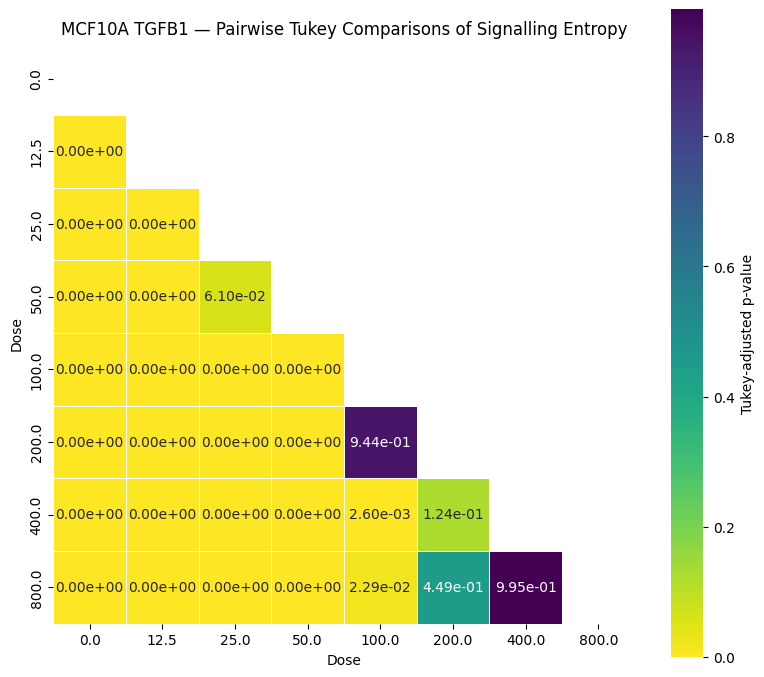

In [27]:
# ============================================================
# CCAT — PAIRWISE TUKEY HEATMAP
# ============================================================

mask = np.triu(
    np.ones_like(ccat_padj, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    ccat_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Tukey-adjusted p-value"
    }
)

plt.title(
    "MCF10A TGFB1 — Pairwise Tukey Comparisons of Signalling Entropy"
)

plt.xlabel("Dose")
plt.ylabel("Dose")

plt.tight_layout()
plt.show()

##### <p style="color:coral">How to interpret the heatmap 

Each cell represents the **Tukey-adjusted p-value** for a pairwise comparison of mean CCAT scores between two dosages. The statistical hypothesis for each comparison is: $$ H_0: \mu_i = \mu_j $$ where $\mu_i$ and $\mu_j$ are the mean CCAT scores for dosages $i$ and $j$. </br>**Adjusted p-value < 0.05:** statistically significant difference in mean CCAT between the two dosages. </br>**Adjusted p-value ≥ 0.05:** no statistically significant difference detected.

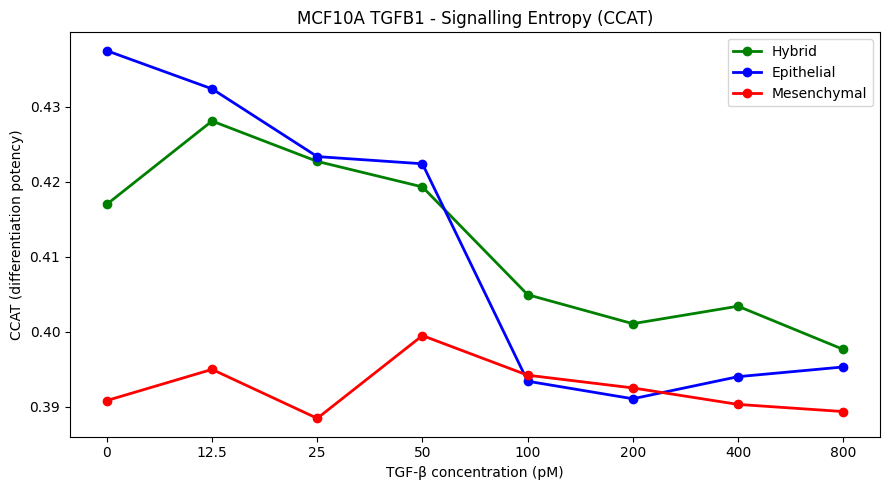

In [28]:
import matplotlib.pyplot as plt
import numpy as np

dose_order = [
    0.0,
    12.5,
    25.0,
    50.0,
    100.0,
    200.0,
    400.0,
    800.0
]

phenotype_colors = {
    "hybrid": "green",
    "epithelial": "blue",
    "mesenchymal": "red"
}

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(dose_order))

for phenotype, color in phenotype_colors.items():

    subset = adata.obs[
        adata.obs["phenotype"] == phenotype
    ]

    means = (
        subset
        .groupby("Dose_pM")["CCAT"]
        .mean()
        .reindex(dose_order)
    )

    ax.plot(
        x,
        means.values,
        marker="o",
        linewidth=2,
        color=color,
        label=phenotype.capitalize()
    )

ax.set_xticks(x)

ax.set_xticklabels([
    f"{dose:g}"
    for dose in dose_order
])

ax.set_xlabel("TGF-β concentration (pM)")
ax.set_ylabel("CCAT (differentiation potency)")

ax.set_title("MCF10A TGFB1 - Signalling Entropy (CCAT)")

ax.legend()

plt.tight_layout()
plt.show()

### <p style="color:pink">Shannon Entropy

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Calculate Shannon entropy per cell
# ------------------------------------------------------------

X = adata.X

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float64)

# Convert expression to probabilities within each cell
row_sums = X.sum(axis=1)

# Avoid division by zero
valid = row_sums > 0

P = np.zeros_like(X)

P[valid] = X[valid] / row_sums[valid, None]

# Shannon entropy
shannon_entropy = np.zeros(X.shape[0])

shannon_entropy[valid] = -np.sum(
    np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),
    axis=1
)

adata.obs["Shannon_entropy"] = shannon_entropy

print(adata.obs["Shannon_entropy"].describe())

/tmp/ipykernel_826872/3058785346.py:30: RuntimeWarning: divide by zero encountered in log
  np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),
/tmp/ipykernel_826872/3058785346.py:30: RuntimeWarning: invalid value encountered in multiply
  np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),


count    8882.000000
mean        6.611467
std         0.169581
min         5.788847
25%         6.507490
50%         6.627420
75%         6.729268
max         7.259260
Name: Shannon_entropy, dtype: float64


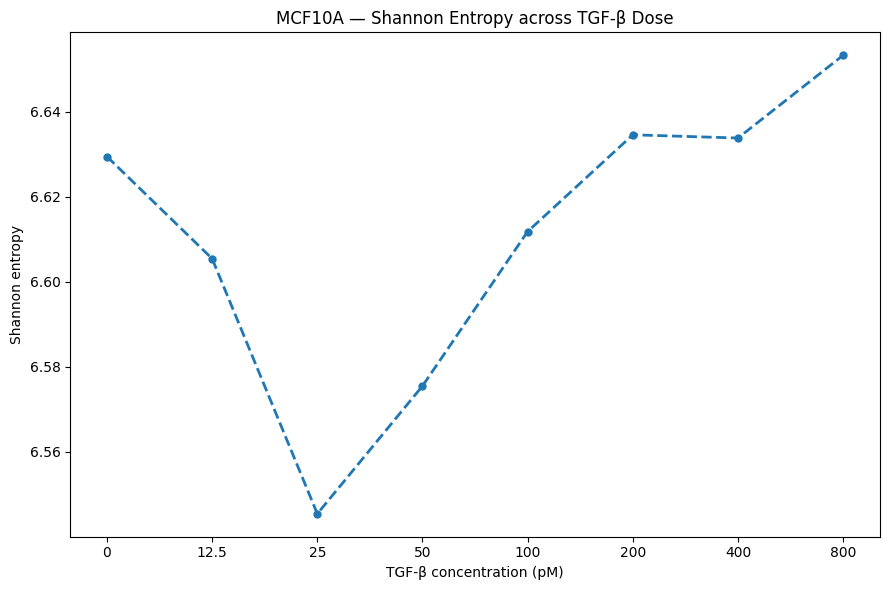

In [29]:
dose_order = [
    0.0,
    12.5,
    25.0,
    50.0,
    100.0,
    200.0,
    400.0,
    800.0
]

entropy_means = (
    adata.obs
    .groupby("Dose_pM")["Shannon_entropy"]
    .mean()
    .reindex(dose_order)
)

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(dose_order))

ax.plot(
    x,
    entropy_means.values,
    "o--",
    linewidth=2,
    markersize=5
)

ax.set_xticks(x)

ax.set_xticklabels([
    f"{dose:g}"
    for dose in dose_order
])

ax.set_xlabel("TGF-β concentration (pM)")
ax.set_ylabel("Shannon entropy")

ax.set_title("MCF10A — Shannon Entropy across TGF-β Dose")

plt.tight_layout()
plt.show()

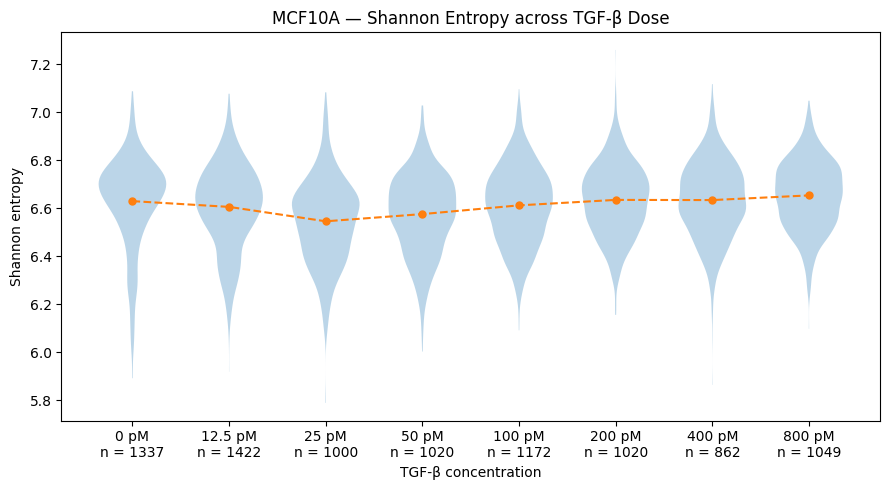

In [30]:
entropy_groups = [
    adata.obs.loc[
        adata.obs["Dose_pM"] == dose,
        "Shannon_entropy"
    ].dropna().values
    for dose in dose_order
]

entropy_means = [
    np.mean(group)
    for group in entropy_groups
]

cell_counts = (
    adata.obs["Dose_pM"]
    .value_counts()
    .reindex(dose_order)
)

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(dose_order))

ax.violinplot(
    entropy_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Mean trajectory
ax.plot(
    positions,
    entropy_means,
    "o--",
    linewidth=1.5,
    markersize=5
)

# Dose + n cells
ax.set_xticks(positions)

ax.set_xticklabels([
    f"{dose:g} pM\nn = {int(cell_counts.loc[dose])}"
    for dose in dose_order
])

ax.set_xlabel("TGF-β concentration")
ax.set_ylabel("Shannon entropy")

ax.set_title("MCF10A — Shannon Entropy across TGF-β Dose")

plt.tight_layout()
plt.show()

In [31]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# TUKEY TEST — SHANNON ENTROPY
# ============================================================

tukey_entropy = pairwise_tukeyhsd(
    endog=adata.obs["Shannon_entropy"],
    groups=adata.obs["Dose_pM"],
    alpha=0.05
)

print(tukey_entropy)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   0.0   12.5   -0.024 0.0039 -0.0433 -0.0048   True
   0.0   25.0  -0.0841    0.0 -0.1052  -0.063   True
   0.0   50.0   -0.054    0.0  -0.075  -0.033   True
   0.0  100.0  -0.0176   0.14 -0.0379  0.0026  False
   0.0  200.0   0.0051 0.9958 -0.0159  0.0261  False
   0.0  400.0   0.0044 0.9989 -0.0177  0.0264  False
   0.0  800.0   0.0238 0.0123   0.003  0.0447   True
  12.5   25.0    -0.06    0.0 -0.0809 -0.0392   True
  12.5   50.0    -0.03 0.0003 -0.0507 -0.0092   True
  12.5  100.0   0.0064 0.9784 -0.0135  0.0263  False
  12.5  200.0   0.0291 0.0005  0.0084  0.0499   True
  12.5  400.0   0.0284  0.002  0.0066  0.0502   True
  12.5  800.0   0.0479    0.0  0.0273  0.0684   True
  25.0   50.0   0.0301 0.0013  0.0076  0.0526   True
  25.0  100.0   0.0664    0.0  0.0447  0.0882   True
  25.0  200.0   0.0892    0.0  0.0667  0.1117 

In [32]:
# ============================================================
# EXTRACT TUKEY RESULTS
# ============================================================

tukey_entropy_df = pd.DataFrame(
    data=tukey_entropy._results_table.data[1:],
    columns=tukey_entropy._results_table.data[0]
)

tukey_entropy_df["p-adj"] = (
    tukey_entropy_df["p-adj"].astype(float)
)


# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

entropy_padj = pd.DataFrame(
    np.nan,
    index=dose_order,
    columns=dose_order
)


for _, row in tukey_entropy_df.iterrows():

    group1 = row["group1"]
    group2 = row["group2"]

    entropy_padj.loc[group1, group2] = row["p-adj"]
    entropy_padj.loc[group2, group1] = row["p-adj"]


display(entropy_padj)

,0.0,12.5,25.0,50.0,100.0,200.0,400.0,800.0
0.0,NaN,0.0039,0.0000,0.0000,0.1400,0.9958,0.9989,0.0123
12.5,0.0039,NaN,0.0000,0.0003,0.9784,0.0005,0.0020,0.0000
25.0,0.0000,0.0000,NaN,0.0013,0.0000,0.0000,0.0000,0.0000
50.0,0.0000,0.0003,0.0013,NaN,0.0000,0.0000,0.0000,0.0000
100.0,0.1400,0.9784,0.0000,0.0000,NaN,0.0310,0.0645,0.0000
200.0,0.9958,0.0005,0.0000,0.0000,0.0310,NaN,1.0000,0.1730
400.0,0.9989,0.0020,0.0000,0.0000,0.0645,1.0000,NaN,0.1778
800.0,0.0123,0.0000,0.0000,0.0000,0.0000,0.1730,0.1778,NaN


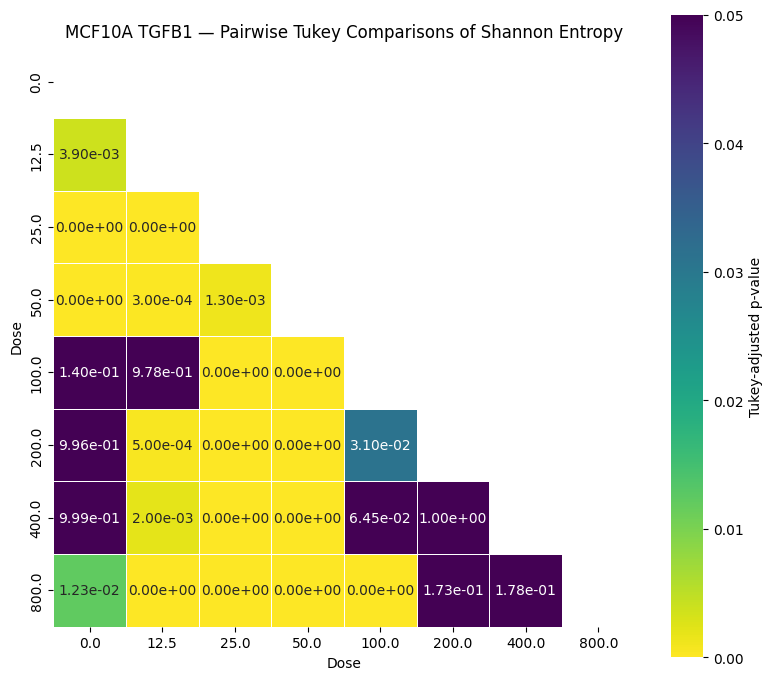

In [33]:
# ============================================================
# SHANNON ENTROPY — PAIRWISE TUKEY HEATMAP
# ============================================================

mask = np.triu(
    np.ones_like(entropy_padj, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    entropy_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Tukey-adjusted p-value"
    }
)

plt.title(
    "MCF10A TGFB1 — Pairwise Tukey Comparisons of Shannon Entropy"
)

plt.xlabel("Dose")
plt.ylabel("Dose")

plt.tight_layout()
plt.show()

### <p style="color:pink">KS and 76GS scores

In [29]:
import sys

repo_root = "/home/csb/Saloni/SCENT/data/EMT_Scoring_KS_76GS"

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from scoring import ks, gs76

##### <p style="color:coral">EMT scoring methods

Two independent EMT scoring methods are imported for comparison:

- **KS score:** a canonical, dataset-independent EMT score based on the Tan et al. EMT gene signatures. More positive values indicate a more **mesenchymal** state, while more negative values indicate a more **epithelial** state.
- **76GS score:** a gene-signature-based EMT score derived from the 76-gene signature. In this implementation, more positive values indicate a more **epithelial** state, while more negative values indicate a more **mesenchymal** state.

These scores provide complementary measures of EMT state that can be compared with the **phenotype classification** and **CCAT/differentiation-potency trajectories** calculated above.

In [30]:
print(type(adata.X))
print(adata.X.shape)

print("layers:", adata.layers.keys())
print("raw:", adata.raw)

<class 'scipy.sparse._csc.csc_matrix'>
(8882, 33694)
layers: KeysView(Layers with keys: )
raw: None


In [31]:
from scoring import signatures

epi = signatures.get("ks_epithelial", "human")
mes = signatures.get("ks_mesenchymal", "human")

print(epi[:20])
print(mes[:20])

['CDH1', 'AGR2', 'EPCAM', 'KRT19', 'RAB25', 'TACSTD2', 'S100P', 'CEACAM6', 'GALNT3', 'FXYD3', 'SPINT2', 'TMEM30B', 'SCNN1A', 'ST14', 'ESRP1', 'S100A14', 'CLDN7', 'ERBB3', 'RBM47', 'SPINT1']
['VIM', 'ZEB1', 'EMP3', 'SACS', 'AXL', 'LOXL2', 'SPARC', 'FHL1', 'FERMT2', 'TUBA1A', 'TMEM158', 'CALD1', 'LGALS1', 'PMP22', 'MSN', 'GLYR1', 'MAP1B', 'AP1S2', 'GJA1', 'DENND5A']


In [32]:
import mygene

mg = mygene.MyGeneInfo()

ks_genes = list(set(epi + mes))

query = mg.querymany(
    ks_genes,
    scopes="symbol",
    fields="ensembl.gene",
    species="human",
    returnall=True
)

symbol_to_ensembl = {}

for q in query["out"]:
    if "ensembl" in q:
        ens = q["ensembl"]

        if isinstance(ens, list):
            ens = ens[0]

        if isinstance(ens, dict):
            ens = ens.get("gene")

        if ens is not None:
            symbol_to_ensembl[q["query"]] = ens

print("Signatures mapped:", len(symbol_to_ensembl), "/", len(ks_genes))

13 input query terms found no hit:	['C1orf106', 'TMEM30B', 'SLC9A3R1', 'PTRF', 'LEPRE1', 'C4orf19', 'GPR56', 'C10orf116', 'KDELC1', 'LH


Signatures mapped: 205 / 218


In [33]:
adata_ks = adata.copy()

In [34]:
epi_ens = [
    symbol_to_ensembl[g]
    for g in epi
    if g in symbol_to_ensembl
    and symbol_to_ensembl[g] in adata_ks.var_names
]

mes_ens = [
    symbol_to_ensembl[g]
    for g in mes
    if g in symbol_to_ensembl
    and symbol_to_ensembl[g] in adata_ks.var_names
]

print("Epithelial:", len(epi_ens), "/", len(epi))
print("Mesenchymal:", len(mes_ens), "/", len(mes))

Epithelial: 156 / 170
Mesenchymal: 43 / 48


In [35]:
# Ensembl -> symbol mapping for genes in your dataset

query = mg.querymany(
    adata_ks.var_names.tolist(),
    scopes="ensembl.gene",
    fields="symbol",
    species="human",
    returnall=True
)

ensembl_to_symbol = {}

for q in query["out"]:
    if "symbol" in q:
        ensembl_to_symbol[q["query"]] = q["symbol"]

print("Mapped:",
      len(ensembl_to_symbol),
      "/",
      adata.n_vars)

24 input query terms found dup hits:	[('ENSG00000117262', 2), ('ENSG00000188092', 2), ('ENSG00000228044', 2), ('ENSG00000226506', 2), ('E
1626 input query terms found no hit:	['ENSG00000238009', 'ENSG00000236743', 'ENSG00000278566', 'ENSG00000273547', 'ENSG00000230699', 'ENS


Mapped: 26106 / 33694


In [28]:
symbols = [
    ensembl_to_symbol.get(g, g)
    for g in adata_magic.var_names
]

print("Unique symbols:", len(set(symbols)))
print("Total genes:", len(symbols))

Unique symbols: 33672
Total genes: 33694


In [29]:
from collections import Counter

symbol_counts = Counter(symbols)

duplicates = {
    symbol: count
    for symbol, count in symbol_counts.items()
    if count > 1
}

print("Number of duplicated symbols:", len(duplicates))
print(duplicates)

Number of duplicated symbols: 22
{'LINC01779': 2, 'GPHRB': 2, 'LINC01115': 2, 'EMC3': 2, 'KCNMB2': 2, 'C2-AS1': 2, 'SYNCRIP': 2, 'RAET1E-AS1': 2, 'GAGE12B': 2, 'LINC03021': 2, 'FAM66E': 2, 'PINX1': 2, 'LINC03023': 2, 'LINC03025': 2, 'ANXA8': 2, 'SSPN-AS1': 2, 'SPATA13': 2, 'PCDH20': 2, 'GOLGA8M': 2, 'CLN3': 2, 'SIGLEC5': 2, 'IGLCOR22-2': 2}


In [30]:
duplicate_symbols = set(duplicates.keys())

print("Duplicated KS epithelial genes:")
print(sorted(duplicate_symbols.intersection(epi)))

print("\nDuplicated KS mesenchymal genes:")
print(sorted(duplicate_symbols.intersection(mes)))

Duplicated KS epithelial genes:
[]

Duplicated KS mesenchymal genes:
[]


In [51]:
print(adata_magic)

AnnData object with n_obs × n_vars = 8882 × 33694
    obs: 'GBC_annot', 'Values', 'Dose_pM'
    uns: 'log1p'


In [56]:
adata_ks = adata.copy()

adata_ks.var_names = symbols

print(adata_ks)

AnnData object with n_obs × n_vars = 8882 × 33694
    obs: 'GBC_annot', 'Values', 'Dose_pM', 'KS_epi', 'KS_mes', 'phenotype', 'CCAT', 'ID'


In [57]:
epi_check = [g for g in epi if g in adata_ks.var_names]
mes_check = [g for g in mes if g in adata_ks.var_names]

print("Epithelial:", len(epi_check), "/", len(epi))
print("Mesenchymal:", len(mes_check), "/", len(mes))

Epithelial: 161 / 170
Mesenchymal: 43 / 48


In [58]:
sc.pp.normalize_total(adata_ks, target_sum=1e4)
sc.pp.log1p(adata_ks)

In [54]:
print(adata_magic.X.max())

2.0393335064666216


In [59]:
ks.score(adata_ks, species="human")

[KS] human: scored 8882 obs (epi 161/170, mes 43/48) -> obs['KS_score']


AnnData object with n_obs × n_vars = 8882 × 33694
    obs: 'GBC_annot', 'Values', 'Dose_pM', 'KS_epi', 'KS_mes', 'phenotype', 'CCAT', 'ID', 'KS_score', 'KS_epi_detected', 'KS_mes_detected'
    uns: 'log1p', 'EMT_scoring'

In [60]:
adata.obs["KS_score"] = adata_ks.obs["KS_score"].values

In [48]:
print(adata.obs["KS_score"].describe())

count    8882.000000
mean        0.122338
std         0.102338
min        -0.247147
25%         0.072656
50%         0.119312
75%         0.182724
max         0.482016
Name: KS_score, dtype: float64


In [49]:
print(
    adata.obs.groupby("Dose_pM")["KS_score"].mean()
)

Dose_pM
0.0     -0.018449
12.5     0.109149
25.0     0.148024
50.0     0.133247
100.0    0.163079
200.0    0.163512
400.0    0.166777
800.0    0.162492
Name: KS_score, dtype: float32


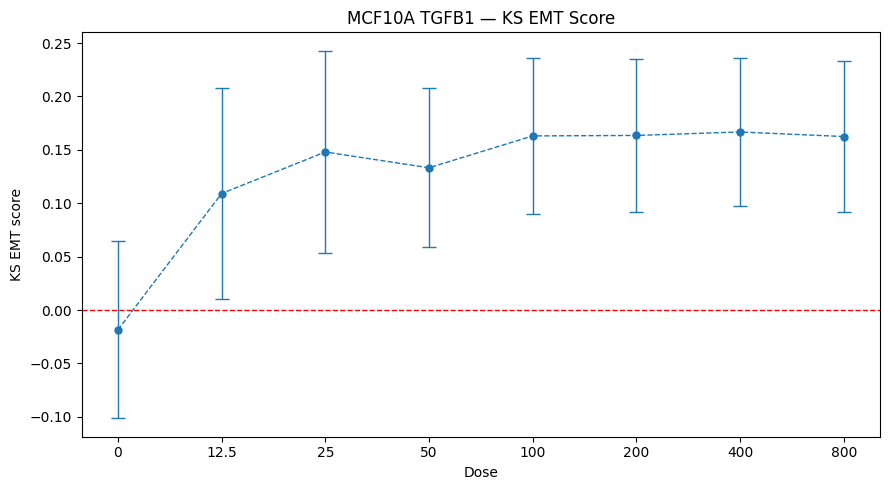

In [51]:
import numpy as np
import matplotlib.pyplot as plt

dose_order = [0, 12.5, 25, 50, 100, 200, 400, 800]

# ============================================================
# KS SCORE — MEAN ± SD
# ============================================================

ks_summary = (
    adata.obs
    .groupby("Dose_pM")["KS_score"]
    .agg(["mean", "std", "count"])
    .reindex(dose_order)
)

x = np.arange(len(dose_order))

plt.figure(figsize=(9, 5))

plt.errorbar(
    x,
    ks_summary["mean"],
    yerr=ks_summary["std"],
    fmt="o--",
    linewidth=1,
    markersize=5,
    capsize=5
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="red"
)

plt.xticks(
    x,
    dose_order
)

plt.xlabel("Dose")
plt.ylabel("KS EMT score")

plt.title("MCF10A TGFB1 — KS EMT Score")

plt.tight_layout()
plt.show()

In [61]:
from scoring import gs76

gs76.score(
    adata_ks,
    species="human",
    score_name="GS76_score"
)

[GS76] human: 64/76 signature genes present.
[GS76] human: scored 8882 obs -> obs['GS76_score']


AnnData object with n_obs × n_vars = 8882 × 33694
    obs: 'GBC_annot', 'Values', 'Dose_pM', 'KS_epi', 'KS_mes', 'phenotype', 'CCAT', 'ID', 'KS_score', 'KS_epi_detected', 'KS_mes_detected', 'GS76_score'
    uns: 'log1p', 'EMT_scoring'
    obsm: 'GS76_contributions'

In [62]:
adata.obs["GS76_score"] = adata_ks.obs["GS76_score"].values

In [54]:
print(adata.obs["GS76_score"].describe())

count    8.882000e+03
mean     7.199825e-18
std      1.575542e+00
min     -2.785088e+00
25%     -1.227160e+00
50%     -3.615052e-01
75%      1.054198e+00
max      5.363026e+00
Name: GS76_score, dtype: float64


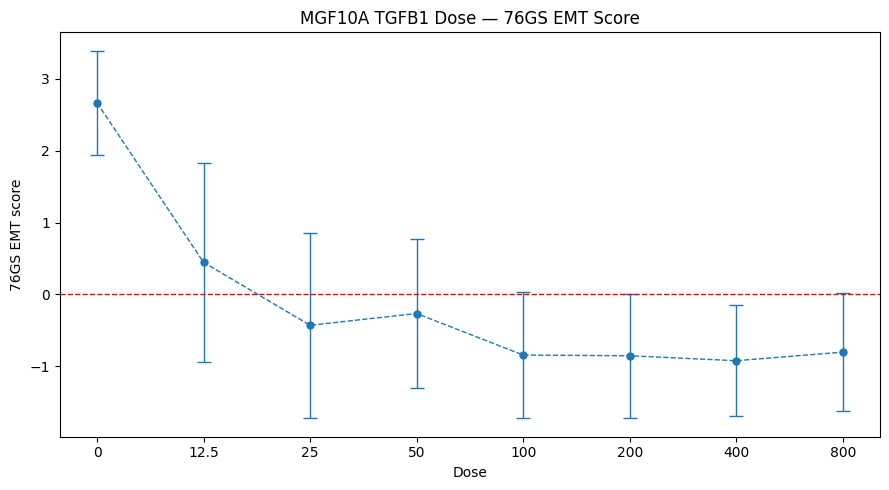

In [55]:
# ============================================================
# 76GS SCORE — MEAN ± SD
# ============================================================

gs76_summary = (
    adata.obs
    .groupby("Dose_pM")["GS76_score"]
    .agg(["mean", "std", "count"])
    .reindex(dose_order)
)

x = np.arange(len(dose_order))

plt.figure(figsize=(9, 5))

plt.errorbar(
    x,
    gs76_summary["mean"],
    yerr=gs76_summary["std"],
    fmt="o--",
    linewidth=1,
    markersize=5,
    capsize=5
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="red"
)

plt.xticks(
    x,
    dose_order
)

plt.xlabel("Dose")
plt.ylabel("76GS EMT score")

plt.title("MGF10A TGFB1 Dose — 76GS EMT Score")

plt.tight_layout()
plt.show()

In [59]:
print(plot_data)

                    KS_score  GS76_score  Dose_pM
AAACCTGAGAAAGTGG-1  0.126824    0.600579     12.5
AAACCTGAGATCACGG-1  0.204247   -0.902177     50.0
AAACCTGAGCTCCTCT-1  0.209158   -0.486282    200.0
AAACCTGAGCTGCAAG-1 -0.053301    2.734022      0.0
AAACCTGAGGCCCTTG-1  0.170157   -0.201526    800.0
...                      ...         ...      ...
TTTGTCAGTCTCAACA-1  0.123646    1.179577     12.5
TTTGTCAGTTCGGGCT-1  0.209013   -0.612296    200.0
TTTGTCATCCCTAACC-1 -0.101401    3.353198      0.0
TTTGTCATCCTTCAAT-1  0.167124   -1.656799    200.0
TTTGTCATCTCTGTCG-1  0.174924   -1.176306    200.0

[8882 rows x 3 columns]


Pearson r = -0.7947, p = 0.0000e+00
Spearman rho = -0.8031, p = 0.0000e+00


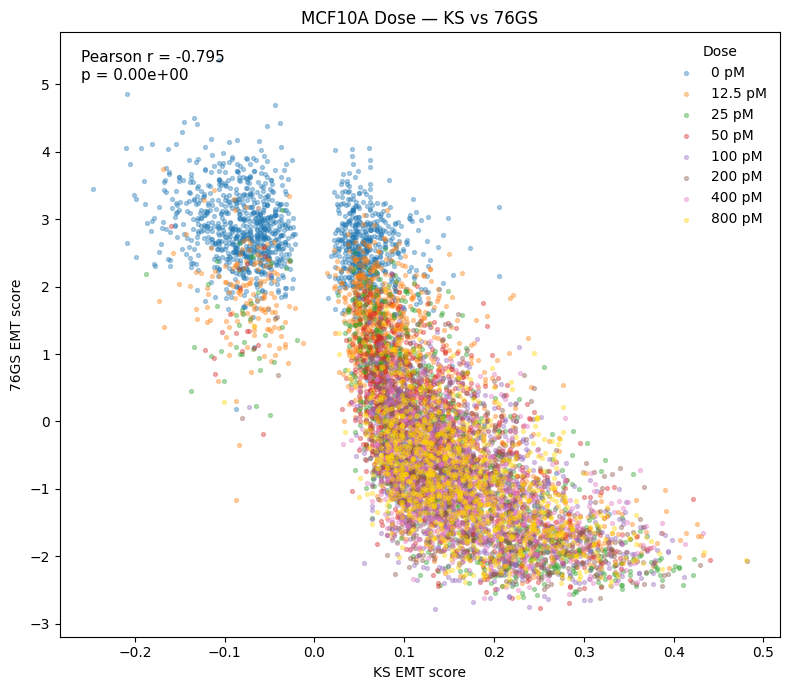

In [63]:
from scipy.stats import pearsonr, spearmanr

dose_order = [0, 12.5, 25, 50, 100, 200, 400, 800]

# ============================================================
# REMOVE MISSING VALUES
# ============================================================

plot_data = adata.obs[
    ["KS_score", "GS76_score", "Dose_pM"]
].dropna()


# ============================================================
# CORRELATIONS
# ============================================================

pearson_r, pearson_p = pearsonr(
    plot_data["KS_score"],
    plot_data["GS76_score"]
)

spearman_r, spearman_p = spearmanr(
    plot_data["KS_score"],
    plot_data["GS76_score"]
)

print(
    f"Pearson r = {pearson_r:.4f}, "
    f"p = {pearson_p:.4e}"
)

print(
    f"Spearman rho = {spearman_r:.4f}, "
    f"p = {spearman_p:.4e}"
)


# ============================================================
# COLORS FOR TIME POINTS
# ============================================================

dose_colors = {
    0.0:    "tab:blue",
    12.5:    "tab:orange",
    25.0:    "tab:green",
    50.0:    "tab:red",
    100.0:    "tab:purple",
    200.0: "tab:brown",
    400.0: "tab:pink",
    800.0: "gold"
}


# ============================================================
# PLOT
# ============================================================

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))

legend_handles = []

for dose in dose_order:

    subset = plot_data[
        plot_data["Dose_pM"] == dose
    ]

    if len(subset) == 0:
        continue

    scatter = ax.scatter(
        subset["KS_score"],
        subset["GS76_score"],
        s=8,
        alpha=0.35,
        color=dose_colors[float(dose)],
        label=f"{dose:g} pM"
    )

    legend_handles.append(scatter)


# ============================================================
# CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\n"
    f"p = {pearson_p:.2e}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11
)


# ============================================================
# LABELS
# ============================================================

ax.set_xlabel("KS EMT score")
ax.set_ylabel("76GS EMT score")

ax.set_title("MCF10A Dose — KS vs 76GS")


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    handles=legend_handles,
    title="Dose",
    frameon=False,
    loc="best"
)

plt.tight_layout()
plt.show()

In [73]:
from itertools import combinations
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# ============================================================
# FUNCTION FOR PAIRWISE WELCH T-TESTS
# ============================================================

def pairwise_welch(
    adata,
    score_column,
    group_column="Dose_pM",
    group_order=None
):

    results = []

    for g1, g2 in combinations(group_order, 2):

        x1 = adata.obs.loc[
            adata.obs[group_column] == g1,
            score_column
        ].dropna()

        x2 = adata.obs.loc[
            adata.obs[group_column] == g2,
            score_column
        ].dropna()

        if len(x1) == 0 or len(x2) == 0:
            continue

        statistic, pvalue = ttest_ind(
            x1,
            x2,
            equal_var=False
        )

        results.append({
            "Group1": g1,
            "Group2": g2,
            "n1": len(x1),
            "n2": len(x2),
            "t_stat": statistic,
            "p_value": pvalue
        })

    results = pd.DataFrame(results)

    # --------------------------------------------------------
    # FDR correction
    # --------------------------------------------------------

    results["p_adj"] = multipletests(
        results["p_value"],
        method="fdr_bh"
    )[1]

    return results

In [74]:
# ============================================================
# KS PAIRWISE COMPARISONS
# ============================================================

ks_pairwise = pairwise_welch(
    adata,
    "KS_score",
    group_order=dose_order
)

display(ks_pairwise)

,Group1,Group2,n1,n2,t_stat,p_value,p_adj
0,0.0,12.5,1337,1422,-36.892315,5.199730e-242,2.079892e-241
1,0.0,25.0,1337,1000,-44.274804,2.446056e-298,1.141493e-297
2,0.0,50.0,1337,1020,-46.654848,0.000000e+00,0.000000e+00
3,0.0,100.0,1337,1172,-58.298894,0.000000e+00,0.000000e+00
4,0.0,200.0,1337,1020,-56.999794,0.000000e+00,0.000000e+00
5,0.0,400.0,1337,862,-56.621896,0.000000e+00,0.000000e+00
6,0.0,800.0,1337,1049,-57.559825,0.000000e+00,0.000000e+00
7,12.5,25.0,1422,1000,-9.776799,3.969323e-22,8.549311e-22
8,12.5,50.0,1422,1020,-6.886707,7.241888e-12,1.192782e-11
9,12.5,100.0,1422,1172,-15.994912,5.781322e-55,1.798634e-54


In [75]:
# ============================================================
# 76GS PAIRWISE COMPARISONS
# ============================================================

gs76_pairwise = pairwise_welch(
    adata,
    "GS76_score",
    group_order=dose_order
)

display(gs76_pairwise)

,Group1,Group2,n1,n2,t_stat,p_value,p_adj
0,0.0,12.5,1337,1422,53.192467,0.000000e+00,0.000000e+00
1,0.0,25.0,1337,1000,68.460104,0.000000e+00,0.000000e+00
2,0.0,50.0,1337,1020,77.387032,0.000000e+00,0.000000e+00
3,0.0,100.0,1337,1172,108.027070,0.000000e+00,0.000000e+00
4,0.0,200.0,1337,1020,105.298684,0.000000e+00,0.000000e+00
5,0.0,400.0,1337,862,108.851432,0.000000e+00,0.000000e+00
6,0.0,800.0,1337,1049,107.913123,0.000000e+00,0.000000e+00
7,12.5,25.0,1422,1000,15.973246,1.756871e-54,4.099366e-54
8,12.5,50.0,1422,1020,14.546474,4.936592e-46,9.873185e-46
9,12.5,100.0,1422,1172,28.747142,8.431827e-157,2.623235e-156


In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# ============================================================
# FUNCTION FOR PAIRWISE WELCH T-TEST + FDR
# ============================================================

def pairwise_padj(data, score_col, dose_order):

    # --------------------------------------------------------
    # Store raw p-values
    # --------------------------------------------------------

    results = []

    for i in range(len(dose_order)):

        for j in range(i + 1, len(dose_order)):

            t1 = dose_order[i]
            t2 = dose_order[j]

            group1 = data.loc[
                data["Dose_pM"] == t1,
                score_col
            ].dropna()

            group2 = data.loc[
                data["Dose_pM"] == t2,
                score_col
            ].dropna()

            # Welch's t-test
            stat, p = ttest_ind(
                group1,
                group2,
                equal_var=False
            )

            results.append({
                "Time1": t1,
                "Time2": t2,
                "p": p
            })


    results = pd.DataFrame(results)


    # --------------------------------------------------------
    # Benjamini-Hochberg FDR correction
    # --------------------------------------------------------

    results["p_adj"] = multipletests(
        results["p"],
        method="fdr_bh"
    )[1]


    # --------------------------------------------------------
    # Create symmetric matrix
    # --------------------------------------------------------

    matrix = pd.DataFrame(
        np.nan,
        index=dose_order,
        columns=dose_order
    )

    for _, row in results.iterrows():

        matrix.loc[row["Time1"], row["Time2"]] = row["p_adj"]
        matrix.loc[row["Time2"], row["Time1"]] = row["p_adj"]


    return matrix, results


# ============================================================
# KS SCORE — PAIRWISE STATISTICS
# ============================================================

ks_padj, ks_results = pairwise_padj(
    adata.obs,
    "KS_score",
    dose_order
)

display(ks_results)


# ============================================================
# 76GS SCORE — PAIRWISE STATISTICS
# ============================================================

gs76_padj, gs76_results = pairwise_padj(
    adata.obs,
    "GS76_score",
    dose_order
)

display(gs76_results)

,Time1,Time2,p,p_adj
0,0.0,12.5,5.199730e-242,2.079892e-241
1,0.0,25.0,2.446056e-298,1.141493e-297
2,0.0,50.0,0.000000e+00,0.000000e+00
3,0.0,100.0,0.000000e+00,0.000000e+00
4,0.0,200.0,0.000000e+00,0.000000e+00
5,0.0,400.0,0.000000e+00,0.000000e+00
6,0.0,800.0,0.000000e+00,0.000000e+00
7,12.5,25.0,3.969323e-22,8.549311e-22
8,12.5,50.0,7.241888e-12,1.192782e-11
9,12.5,100.0,5.781322e-55,1.798634e-54


,Time1,Time2,p,p_adj
0,0.0,12.5,0.000000e+00,0.000000e+00
1,0.0,25.0,0.000000e+00,0.000000e+00
2,0.0,50.0,0.000000e+00,0.000000e+00
3,0.0,100.0,0.000000e+00,0.000000e+00
4,0.0,200.0,0.000000e+00,0.000000e+00
5,0.0,400.0,0.000000e+00,0.000000e+00
6,0.0,800.0,0.000000e+00,0.000000e+00
7,12.5,25.0,1.756871e-54,4.099366e-54
8,12.5,50.0,4.936592e-46,9.873185e-46
9,12.5,100.0,8.431827e-157,2.623235e-156


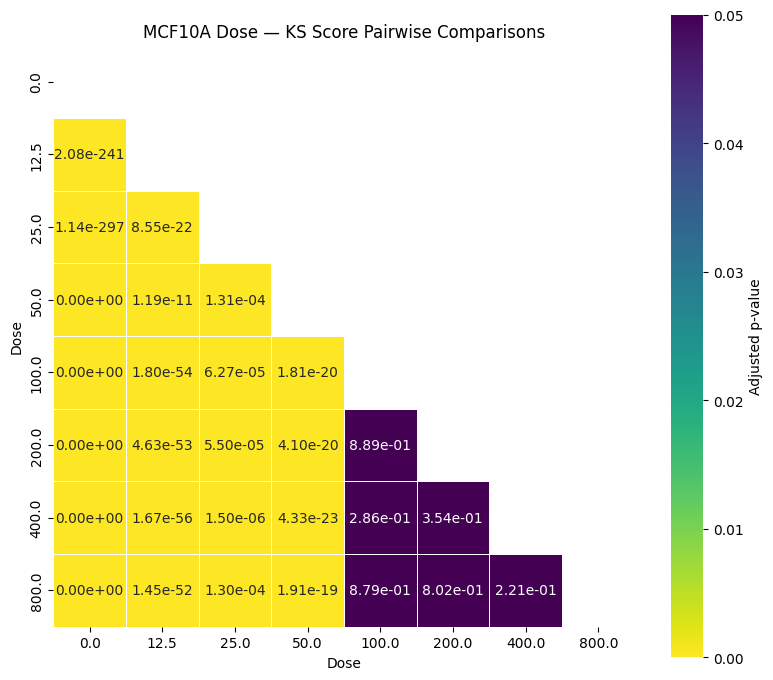

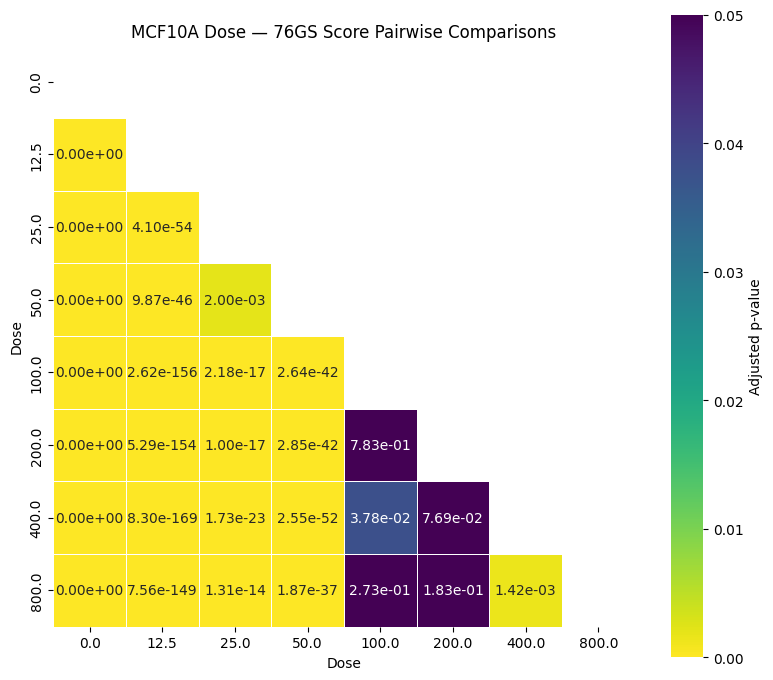

In [77]:
# ============================================================
# KS HEATMAP — LOWER TRIANGLE ONLY
# ============================================================

mask = np.triu(
    np.ones_like(ks_padj, dtype=bool)
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    ks_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Adjusted p-value"}
)

plt.title("MCF10A Dose — KS Score Pairwise Comparisons")
plt.xlabel("Dose")
plt.ylabel("Dose")

plt.tight_layout()
plt.show()


# ============================================================
# 76GS HEATMAP — LOWER TRIANGLE ONLY
# ============================================================

mask = np.triu(
    np.ones_like(gs76_padj, dtype=bool)
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    gs76_padj,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Adjusted p-value"}
)

plt.title("MCF10A Dose — 76GS Score Pairwise Comparisons")
plt.xlabel("Dose")
plt.ylabel("Dose")

plt.tight_layout()
plt.show()

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

In [36]:
import pandas as pd
import numpy as np

id_df = pd.read_excel("/home/csb/Saloni/SCENT/data/ID/MCF10A_Dose_ID_local.xlsx")

print(id_df.head())
print(id_df.columns)

           Unnamed: 0        ID
0  AAACCTGAGAAAGTGG-1  0.335918
1  AAACCTGAGATCACGG-1  0.369625
2  AAACCTGAGCTCCTCT-1  0.338579
3  AAACCTGAGCTGCAAG-1  0.210675
4  AAACCTGAGGCCCTTG-1  0.543920
Index(['Unnamed: 0', 'ID'], dtype='object')


In [37]:
id_df = id_df.set_index(id_df.columns[0])

id_df.index = id_df.index.astype(str)

In [38]:
adata.obs["ID"] = id_df["ID"].reindex(adata.obs_names)

In [44]:
print(adata.obs['CCAT'])

AAACCTGAGAAAGTGG-1    0.451933
AAACCTGAGATCACGG-1    0.419302
AAACCTGAGCTCCTCT-1    0.409257
AAACCTGAGCTGCAAG-1    0.440689
AAACCTGAGGCCCTTG-1    0.396877
                        ...   
TTTGTCAGTCTCAACA-1    0.441266
TTTGTCAGTTCGGGCT-1    0.385828
TTTGTCATCCCTAACC-1    0.469328
TTTGTCATCCTTCAAT-1    0.410739
TTTGTCATCTCTGTCG-1    0.408220
Name: CCAT, Length: 8882, dtype: float32


In [41]:
print(adata.obs[["ID", "Dose_pM"]].head())

print("Cells in adata:", adata.n_obs)
print("Cells with ID:", adata.obs["ID"].notna().sum())
print("Missing ID:", adata.obs["ID"].isna().sum())

                          ID  Dose_pM
AAACCTGAGAAAGTGG-1  0.335918     12.5
AAACCTGAGATCACGG-1  0.369625     50.0
AAACCTGAGCTCCTCT-1  0.338579    200.0
AAACCTGAGCTGCAAG-1  0.210675      0.0
AAACCTGAGGCCCTTG-1  0.543920    800.0
Cells in adata: 8882
Cells with ID: 8882
Missing ID: 0


In [42]:
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt

plot_data = adata.obs[
    ["ID", "CCAT", "Dose_pM"]
].dropna()

# ============================================================
# CORRELATION
# ============================================================

pearson_r, pearson_p = pearsonr(
    plot_data["ID"],
    plot_data["CCAT"]
)

spearman_r, spearman_p = spearmanr(
    plot_data["ID"],
    plot_data["CCAT"]
)

print(f"Pearson r = {pearson_r:.4f}, p = {pearson_p:.4e}")
print(f"Spearman rho = {spearman_r:.4f}, p = {spearman_p:.4e}")

Pearson r = 0.1283, p = 6.2044e-34
Spearman rho = 0.1300, p = 8.8805e-35


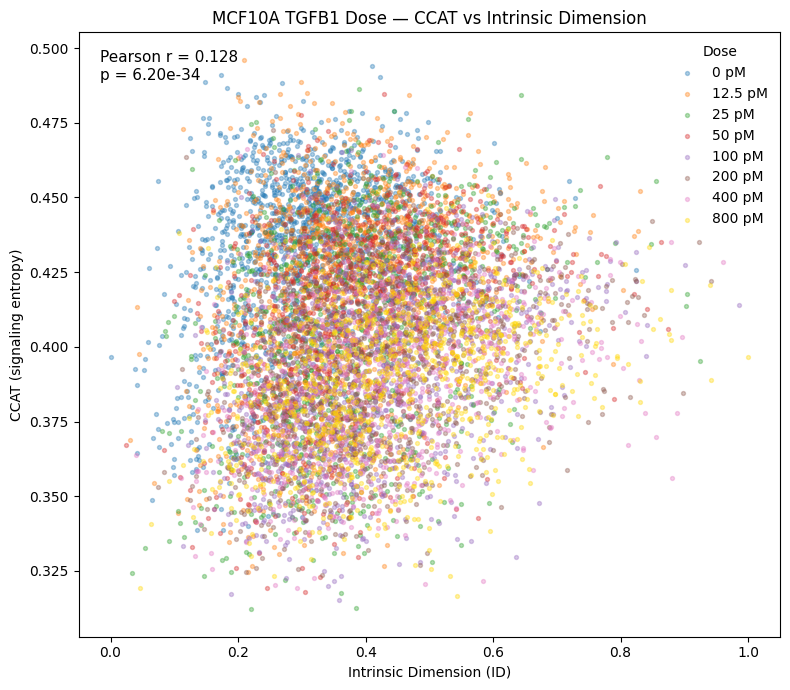

In [45]:
# ============================================================
# DOSE ORDER
# ============================================================

dose_order = [
    0.0,
    12.5,
    25.0,
    50.0,
    100.0,
    200.0,
    400.0,
    800.0
]


# ============================================================
# COLORS
# ============================================================

dose_colors = {
    0.0:   "tab:blue",
    12.5:  "tab:orange",
    25.0:  "tab:green",
    50.0:  "tab:red",
    100.0: "tab:purple",
    200.0: "tab:brown",
    400.0: "tab:pink",
    800.0: "gold"
}


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 7))

for dose in dose_order:

    subset = plot_data[
        plot_data["Dose_pM"] == dose
    ]

    if len(subset) == 0:
        continue

    plt.scatter(
        subset["ID"],
        subset["CCAT"],
        s=8,
        alpha=0.35,
        color=dose_colors[dose],
        label=f"{dose:g} pM"
    )


# ============================================================
# CORRELATION ANNOTATION
# ============================================================

plt.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\n"
    f"p = {pearson_p:.2e}",
    transform=plt.gca().transAxes,
    ha="left",
    va="top",
    fontsize=11
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel("Intrinsic Dimension (ID)")
plt.ylabel("CCAT (signaling entropy)")

plt.title(
    "MCF10A TGFB1 Dose — CCAT vs Intrinsic Dimension"
)

plt.legend(
    title="Dose",
    frameon=False
)

plt.tight_layout()
plt.show()

In [65]:
print(adata)

AnnData object with n_obs × n_vars = 8882 × 33694
    obs: 'GBC_annot', 'Values', 'Dose_pM', 'KS_epi', 'KS_mes', 'phenotype', 'CCAT', 'ID', 'KS_score', 'GS76_score'


In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

from scoring import signatures


# ============================================================
# 1. GET KS SIGNATURES
# ============================================================

epi_genes = signatures.get("ks_epithelial", "human")
mes_genes = signatures.get("ks_mesenchymal", "human")

epi_genes = [g for g in epi_genes if g in adata.var_names]
mes_genes = [g for g in mes_genes if g in adata.var_names]

print("Epithelial genes present:", len(epi_genes))
print("Mesenchymal genes present:", len(mes_genes))


# ============================================================
# 2. MAKE NORMALIZED COPY
# ============================================================

adata_ks = adata.copy()

sc.pp.normalize_total(
    adata_ks,
    target_sum=1e4
)

sc.pp.log1p(adata_ks)


# ============================================================
# 3. EXTRACT SIGNATURE EXPRESSION
# ============================================================

epi_idx = [
    adata_ks.var_names.get_loc(g)
    for g in epi_genes
]

mes_idx = [
    adata_ks.var_names.get_loc(g)
    for g in mes_genes
]

epi_X = adata_ks.X[:, epi_idx]
mes_X = adata_ks.X[:, mes_idx]

if hasattr(epi_X, "toarray"):
    epi_X = epi_X.toarray()

if hasattr(mes_X, "toarray"):
    mes_X = mes_X.toarray()

epi_X = np.asarray(epi_X)
mes_X = np.asarray(mes_X)


# ============================================================
# 4. CALCULATE PER-CELL SIGNATURE SCORES
# ============================================================

adata.obs["KS_epi_score"] = np.mean(
    epi_X,
    axis=1
)

adata.obs["KS_mes_score"] = np.mean(
    mes_X,
    axis=1
)


print(adata.obs[
    ["KS_epi_score", "KS_mes_score"]
].describe())


# ============================================================
# 5. PREPARE PLOT DATA
# ============================================================

plot_data = adata.obs[
    [
        "KS_epi_score",
        "KS_mes_score",
        "Dose_pM"
    ]
].dropna()


# ============================================================
# 6. CORRELATION
# ============================================================

pearson_r, pearson_p = pearsonr(
    plot_data["KS_epi_score"],
    plot_data["KS_mes_score"]
)

spearman_r, spearman_p = spearmanr(
    plot_data["KS_epi_score"],
    plot_data["KS_mes_score"]
)

print(f"Pearson r = {pearson_r:.4f}")
print(f"Pearson p = {pearson_p:.4e}")
print(f"Spearman rho = {spearman_r:.4f}")
print(f"Spearman p = {spearman_p:.4e}")


# ============================================================
# 7. DOSE ORDER
# ============================================================

dose_order = [
    0.0,
    12.5,
    25.0,
    50.0,
    100.0,
    200.0,
    400.0,
    800.0
]


# ============================================================
# 8. COLORS
# ============================================================

dose_colors = {
    0.0:   "tab:blue",
    12.5:  "tab:orange",
    25.0:  "tab:green",
    50.0:  "tab:red",
    100.0: "tab:purple",
    200.0: "tab:brown",
    400.0: "tab:pink",
    800.0: "tab:gray"
}


# ============================================================
# 9. SCATTER PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))

for dose in dose_order:

    subset = plot_data[
        plot_data["Dose_pM"] == dose
    ]

    if len(subset) == 0:
        continue

    ax.scatter(
        subset["KS_epi_score"],
        subset["KS_mes_score"],
        s=8,
        alpha=0.35,
        color=dose_colors[dose],
        label=f"{dose:g} pM"
    )


# ============================================================
# 10. CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\n"
    f"p = {pearson_p:.2e}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11
)


# ============================================================
# 11. FORMATTING
# ============================================================

ax.set_xlabel("KS epithelial score")
ax.set_ylabel("KS mesenchymal score")

ax.set_title(
    "MCF10A Dose — KS Epithelial vs Mesenchymal"
)

ax.legend(
    title="TGF-β dose",
    frameon=False
)

plt.tight_layout()
plt.show()

Epithelial genes present: 0
Mesenchymal genes present: 0
       KS_epi_score  KS_mes_score
count           0.0           0.0
mean            NaN           NaN
std             NaN           NaN
min             NaN           NaN
25%             NaN           NaN
50%             NaN           NaN
75%             NaN           NaN
max             NaN           NaN


/home/csb/Saloni/SCENT/.venv/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/csb/Saloni/SCENT/.venv/lib/python3.10/site-packages/numpy/_core/_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/home/csb/Saloni/SCENT/.venv/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/csb/Saloni/SCENT/.venv/lib/python3.10/site-packages/numpy/_core/_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


ValueError: `x` and `y` must have length at least 2.

In [38]:
print(adata.var.columns)

Index([], dtype='object')


In [49]:
# Check what the gene IDs in your AnnData look like

print("Number of genes:", adata.n_vars)

print("\nFirst 20 var_names:")
print(adata.var_names[:20].tolist())

print("\nvar_names dtype:")
print(adata.var_names.dtype)

print("\nvar columns:")
print(adata.var.columns.tolist())

print("\nFirst 5 rows of adata.var:")
print(adata.var.head())

Number of genes: 33694

First 20 var_names:
['ENSG00000243485', 'ENSG00000237613', 'ENSG00000186092', 'ENSG00000238009', 'ENSG00000239945', 'ENSG00000239906', 'ENSG00000241599', 'ENSG00000279928', 'ENSG00000279457', 'ENSG00000228463', 'ENSG00000236743', 'ENSG00000236601', 'ENSG00000237094', 'ENSG00000278566', 'ENSG00000230021', 'ENSG00000235146', 'ENSG00000273547', 'ENSG00000229905', 'ENSG00000237491', 'ENSG00000177757']

var_names dtype:
object

var columns:
[]

First 5 rows of adata.var:
Empty DataFrame
Columns: []
Index: [ENSG00000243485, ENSG00000237613, ENSG00000186092, ENSG00000238009, ENSG00000239945]


In [50]:
ensembl_ids = adata.var_names.tolist()

print("Number of Ensembl IDs:", len(ensembl_ids))
print("First 10:")
print(ensembl_ids[:10])

Number of Ensembl IDs: 33694
First 10:
['ENSG00000243485', 'ENSG00000237613', 'ENSG00000186092', 'ENSG00000238009', 'ENSG00000239945', 'ENSG00000239906', 'ENSG00000241599', 'ENSG00000279928', 'ENSG00000279457', 'ENSG00000228463']


In [51]:
import mygene

mg = mygene.MyGeneInfo()

results = mg.querymany(
    ensembl_ids,
    scopes="ensembl.gene",
    fields="symbol",
    species="human",
    as_dataframe=True
)

print(results.head())

24 input query terms found dup hits:	[('ENSG00000117262', 2), ('ENSG00000188092', 2), ('ENSG00000228044', 2), ('ENSG00000226506', 2), ('E
1626 input query terms found no hit:	['ENSG00000238009', 'ENSG00000236743', 'ENSG00000278566', 'ENSG00000273547', 'ENSG00000230699', 'ENS


                             _id     _score       symbol notfound
query                                                            
ENSG00000243485  ENSG00000243485  32.379210  MIR1302-2HG      NaN
ENSG00000237613           645520  32.379814      FAM138A      NaN
ENSG00000186092            79501  31.399532        OR4F5      NaN
ENSG00000238009              NaN        NaN          NaN     True
ENSG00000239945  ENSG00000239945  32.378690          NaN      NaN


In [52]:
# ============================================================
# CREATE ENSEMBL → GENE SYMBOL MAPPING
# ============================================================

# Keep only mappings where a gene symbol was found
mapping_df = results[
    results["symbol"].notna()
].copy()

# Create dictionary
ensembl_to_symbol = dict(
    zip(
        mapping_df.index,
        mapping_df["symbol"]
    )
)

print("Mapped genes:", len(ensembl_to_symbol))

print("\nFirst 10 mappings:")
for ensembl, symbol in list(ensembl_to_symbol.items())[:10]:
    print(ensembl, "→", symbol)

Mapped genes: 26106

First 10 mappings:
ENSG00000243485 → MIR1302-2HG
ENSG00000237613 → FAM138A
ENSG00000186092 → OR4F5
ENSG00000279928 → DDX11L17
ENSG00000279457 → WASH9P
ENSG00000228463 → RPL23AP21
ENSG00000237491 → LINC01409
ENSG00000177757 → FAM87B
ENSG00000225880 → LINC00115
ENSG00000230368 → FAM41C


In [53]:
signatures.get("ks_epithelial", "human")
signatures.get("ks_mesenchymal", "human")

['VIM',
 'ZEB1',
 'EMP3',
 'SACS',
 'AXL',
 'LOXL2',
 'SPARC',
 'FHL1',
 'FERMT2',
 'TUBA1A',
 'TMEM158',
 'CALD1',
 'LGALS1',
 'PMP22',
 'MSN',
 'GLYR1',
 'MAP1B',
 'AP1S2',
 'GJA1',
 'DENND5A',
 'C12orf24',
 'TPM2',
 'TUBB6',
 'SRPX',
 'ANK2',
 'CHN1',
 'SH2B3',
 'LEPRE1',
 'ETV1',
 'SOBP',
 'AKAP12',
 'TGFB1I1',
 'SERPINE1',
 'SOAT1',
 'COL5A2',
 'LHFP',
 'CEP170',
 'POPDC3',
 'TRPC1',
 'KDELC1',
 'MYL9',
 'BAG2',
 'FSTL1',
 'MXRA7',
 'GFPT2',
 'RECK',
 'TMEFF1',
 'PTRF']

In [54]:
# ============================================================
# ADD GENE SYMBOLS TO adata.var
# ============================================================

adata.var["gene_symbol"] = [
    ensembl_to_symbol.get(gene_id, np.nan)
    for gene_id in adata.var_names
]

print(adata.var.head(10))

print(
    "\nGenes with symbols:",
    adata.var["gene_symbol"].notna().sum()
)

                 gene_symbol
ENSG00000243485  MIR1302-2HG
ENSG00000237613      FAM138A
ENSG00000186092        OR4F5
ENSG00000238009          NaN
ENSG00000239945          NaN
ENSG00000239906          NaN
ENSG00000241599          NaN
ENSG00000279928     DDX11L17
ENSG00000279457       WASH9P
ENSG00000228463    RPL23AP21

Genes with symbols: 26106


In [55]:
# ============================================================
# GET KS SIGNATURES
# ============================================================

epi_genes = signatures.get("ks_epithelial", "human")
mes_genes = signatures.get("ks_mesenchymal", "human")

print("Total epithelial signature genes:", len(epi_genes))
print("Total mesenchymal signature genes:", len(mes_genes))


# ============================================================
# MATCH AGAINST MAPPED SYMBOLS
# ============================================================

mapped_symbols = set(
    adata.var["gene_symbol"].dropna()
)

epi_found = [
    gene for gene in epi_genes
    if gene in mapped_symbols
]

mes_found = [
    gene for gene in mes_genes
    if gene in mapped_symbols
]

print("\nEpithelial genes found:", len(epi_found))
print("Mesenchymal genes found:", len(mes_found))

print("\nEpithelial examples:", epi_found[:20])
print("Mesenchymal examples:", mes_found[:20])

Total epithelial signature genes: 170
Total mesenchymal signature genes: 48

Epithelial genes found: 161
Mesenchymal genes found: 43

Epithelial examples: ['CDH1', 'AGR2', 'EPCAM', 'KRT19', 'RAB25', 'TACSTD2', 'S100P', 'CEACAM6', 'GALNT3', 'FXYD3', 'SPINT2', 'SCNN1A', 'ST14', 'ESRP1', 'S100A14', 'CLDN7', 'ERBB3', 'RBM47', 'SPINT1', 'ELF3']
Mesenchymal examples: ['VIM', 'ZEB1', 'EMP3', 'SACS', 'AXL', 'LOXL2', 'SPARC', 'FHL1', 'FERMT2', 'TUBA1A', 'TMEM158', 'CALD1', 'LGALS1', 'PMP22', 'MSN', 'GLYR1', 'MAP1B', 'AP1S2', 'GJA1', 'DENND5A']


In [56]:
# ============================================================
# GET EXPRESSION FOR MAPPED KS GENES
# ============================================================

# Map gene symbol -> Ensembl ID
symbol_to_ensembl = {}

for ensembl_id, symbol in ensembl_to_symbol.items():
    if symbol not in symbol_to_ensembl:
        symbol_to_ensembl[symbol] = ensembl_id


# Keep only signatures that are actually present
epi_ensembl = [
    symbol_to_ensembl[g]
    for g in epi_found
    if g in symbol_to_ensembl
]

mes_ensembl = [
    symbol_to_ensembl[g]
    for g in mes_found
    if g in symbol_to_ensembl
]

print("Epithelial genes used:", len(epi_ensembl))
print("Mesenchymal genes used:", len(mes_ensembl))

Epithelial genes used: 161
Mesenchymal genes used: 43


In [57]:
# ============================================================
# EXTRACT EXPRESSION FOR KS SIGNATURE GENES
# ============================================================

epi_idx = [
    adata.var_names.get_loc(gene_id)
    for gene_id in epi_ensembl
]

mes_idx = [
    adata.var_names.get_loc(gene_id)
    for gene_id in mes_ensembl
]


X = adata.X

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X)


# ============================================================
# PER-CELL KS EPI / KS MES EXPRESSION
# ============================================================

adata.obs["KS_epi"] = X[:, epi_idx].mean(axis=1)

adata.obs["KS_mes"] = X[:, mes_idx].mean(axis=1)


print(adata.obs[["KS_epi", "KS_mes"]].describe())

            KS_epi       KS_mes
count  8882.000000  8882.000000
mean      0.960763     2.863707
std       0.594672     1.150465
min       0.062112     0.232558
25%       0.546584     2.046512
50%       0.807453     2.697675
75%       1.229814     3.511628
max       5.204969     9.697675


Pearson r = 0.0164, p = 1.2218e-01
Spearman rho = 0.0213, p = 4.4651e-02


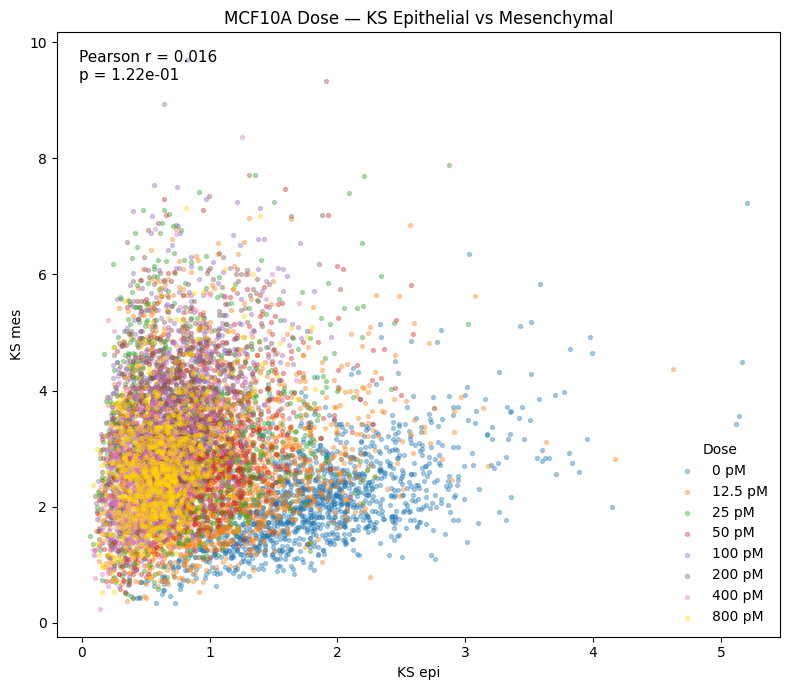

In [58]:
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt


# ============================================================
# DOSE ORDER
# ============================================================

dose_order = [
    0,
    12.5,
    25,
    50,
    100,
    200,
    400,
    800
]


# ============================================================
# COLORS
# ============================================================

dose_colors = {
    0.0:   "tab:blue",
    12.5:  "tab:orange",
    25.0:  "tab:green",
    50.0:  "tab:red",
    100.0: "tab:purple",
    200.0: "tab:brown",
    400.0: "tab:pink",
    800.0: "gold"
}


# ============================================================
# REMOVE MISSING VALUES
# ============================================================

plot_data = adata.obs[
    ["KS_epi", "KS_mes", "Dose_pM"]
].dropna()


# ============================================================
# CORRELATIONS
# ============================================================

pearson_r, pearson_p = pearsonr(
    plot_data["KS_epi"],
    plot_data["KS_mes"]
)

spearman_r, spearman_p = spearmanr(
    plot_data["KS_epi"],
    plot_data["KS_mes"]
)


print(
    f"Pearson r = {pearson_r:.4f}, "
    f"p = {pearson_p:.4e}"
)

print(
    f"Spearman rho = {spearman_r:.4f}, "
    f"p = {spearman_p:.4e}"
)


# ============================================================
# SCATTER PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))


for dose in dose_order:

    subset = plot_data[
        plot_data["Dose_pM"] == dose
    ]

    if len(subset) == 0:
        continue

    ax.scatter(
        subset["KS_epi"],
        subset["KS_mes"],
        s=8,
        alpha=0.35,
        color=dose_colors[float(dose)],
        label=f"{dose:g} pM"
    )


# ============================================================
# CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\n"
    f"p = {pearson_p:.2e}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11
)


# ============================================================
# LABELS
# ============================================================

ax.set_xlabel("KS epi")
ax.set_ylabel("KS mes")

ax.set_title(
    "MCF10A Dose — KS Epithelial vs Mesenchymal"
)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    title="Dose",
    frameon=False,
    loc="best"
)

plt.tight_layout()
plt.show()